## 1. Import library dan konfigurasi

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("/content/drive/MyDrive/Data Penjualan UMKM for AI Agent/clean-indonesia_ecommerce_cleaned.csv")

## 2. Load data dan validasi struktur

In [3]:
df = pd.read_csv(DATA_PATH, sep=None, engine="python")

print("Shape:", df.shape)
print("Kolom:", df.columns.tolist())
display(df.head())

Shape: (18868, 19)
Kolom: ['order_id', 'total_qty', 'total_weight_gr', 'total_returned_qty', 'Total Diskon', 'product_categories', 'num_product_categories', 'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman', 'Metode Pembayaran', 'Kota/Kabupaten', 'Provinsi', 'Ongkos Kirim Dibayar oleh Pembeli', 'Estimasi Potongan Biaya Pengiriman', 'Total Pembayaran', 'Perkiraan Ongkos Kirim', 'Waktu Pesanan Dibuat', 'order_date']


,order_id,total_qty,total_weight_gr,total_returned_qty,Total Diskon,product_categories,num_product_categories,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Waktu Pesanan Dibuat,order_date
0,ORD_0000001,2.0,2000,0,0,Celengan,1,Selesai,Tidak dibatalkan,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15:00,2024-04-01 00:00:00
1,ORD_0000002,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47:00,2024-04-01 00:00:00
2,ORD_0000003,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25:00,2024-04-01 00:00:00
3,ORD_0000004,2.0,400,0,0,Mangkok Sambal / Saus,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41:00,2024-04-01 00:00:00
4,ORD_0000005,3.0,3600,0,0,"Keranjang, Other, Tempat Nasi",3,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA TANGERANG,BANTEN,0,0,0,8000,2024-04-01 06:12:00,2024-04-01 00:00:00


In [4]:
required_columns = [
    "order_id", "total_qty", "product_categories", "Status Pesanan",
    "Metode Pembayaran", "Provinsi", "Total Pembayaran",
    "Waktu Pesanan Dibuat", "order_date"
]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_count": df.nunique(dropna=True)
})
display(quality)

print("Duplikasi seluruh baris:", int(df.duplicated().sum()))
print("Duplikasi order_id:", int(df["order_id"].duplicated().sum()))


,dtype,missing_count,missing_pct,unique_count
order_id,object,0,0.0,18868
total_qty,float64,0,0.0,57
total_weight_gr,int64,0,0.0,605
total_returned_qty,int64,0,0.0,10
Total Diskon,int64,0,0.0,47
product_categories,object,0,0.0,640
num_product_categories,int64,0,0.0,10
Status Pesanan,object,0,0.0,11
Alasan Pembatalan,object,0,0.0,19
Opsi Pengiriman,object,0,0.0,45


Duplikasi seluruh baris: 0
Duplikasi order_id: 0


## 3. Validasi tanggal dan status

`order_date` digunakan sebagai tanggal analisis. `Waktu Pesanan Dibuat` dipakai sebagai pembanding dan fallback bila `order_date` kosong. Perbedaan tanggal antar-kolom dilaporkan, bukan diabaikan.


In [5]:
df = df.copy()
df["order_date_parsed"] = pd.to_datetime(df["order_date"], errors="coerce")
df["created_at_parsed"] = pd.to_datetime(df["Waktu Pesanan Dibuat"], errors="coerce")

date_recoverable = df["order_date_parsed"].isna() & df["created_at_parsed"].notna()
df["analysis_date"] = df["order_date_parsed"].fillna(df["created_at_parsed"])

both_dates = df["order_date_parsed"].notna() & df["created_at_parsed"].notna()
date_mismatch = (
    df.loc[both_dates, "order_date_parsed"].dt.date
    != df.loc[both_dates, "created_at_parsed"].dt.date
)

print("order_date gagal parse:", int(df["order_date_parsed"].isna().sum()))
print("Tanggal dapat dipulihkan dari timestamp:", int(date_recoverable.sum()))
print("Baris kedua tanggal tersedia:", int(both_dates.sum()))
print("Tanggal berbeda pada dua kolom:", int(date_mismatch.sum()))

# Normalisasi status tanggal pengembalian menjadi satu label.
status = df["Status Pesanan"].astype("string").str.strip()
df["status_normalized"] = status.mask(
    status.str.startswith("Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian", na=False),
    "Dalam Masa Pengembalian"
)
display(df["status_normalized"].value_counts(dropna=False).to_frame("jumlah_order"))


order_date gagal parse: 0
Tanggal dapat dipulihkan dari timestamp: 0
Baris kedua tanggal tersedia: 18868
Tanggal berbeda pada dua kolom: 0


,jumlah_order
status_normalized,
Selesai,16045
Batal,2573
Dalam Masa Pengembalian,161
Sedang Dikirim,59
Telah Dikirim,30


## 4. Missing value dan keputusan imputasi

Tidak melakukan imputasi `total_qty` pada tahap ini. Rata-rata kuantitas dihitung hanya dari nilai valid dan jumlah missing dilaporkan. Nilai kosong metode pembayaran dipertahankan sebagai `Unknown` hanya untuk kebutuhan segmentasi, tanpa menyimpulkan bahwa itu COD.


In [6]:
df["total_qty"] = pd.to_numeric(df["total_qty"], errors="coerce")
df["Total Pembayaran"] = pd.to_numeric(df["Total Pembayaran"], errors="coerce")

df["qty_missing"] = df["total_qty"].isna()
df["payment_method_analysis"] = (
    df["Metode Pembayaran"].astype("string").fillna("Unknown").str.strip()
)

print("Missing total_qty:", int(df["qty_missing"].sum()))
print("Missing metode pembayaran:", int(df["Metode Pembayaran"].isna().sum()))
print("Rata-rata qty dari nilai valid:", round(df["total_qty"].mean(), 3))
print("Median qty dari nilai valid:", round(df["total_qty"].median(), 3))


Missing total_qty: 0
Missing metode pembayaran: 0
Rata-rata qty dari nilai valid: 2.542
Median qty dari nilai valid: 1.0


## 5. KPI bisnis dengan definisi eksplisit

- **Total orders:** jumlah `order_id` unik, mencakup seluruh status.
- **Completed orders:** jumlah order berstatus `Selesai`.
- **Cancelled orders:** jumlah order berstatus `Batal`.
- **Cancellation rate:** `Batal / seluruh order unik × 100%`. Denominator mencakup semua status, termasuk order berjalan.
- **AOV:** rata-rata `Total Pembayaran` untuk order `Selesai` saja. Laporkan mean dan median karena distribusi pembayaran miring.


In [7]:
total_orders = df["order_id"].nunique()
completed = df[df["status_normalized"].eq("Selesai")].copy()
cancelled = df[df["status_normalized"].eq("Batal")].copy()

completed_payment = completed["Total Pembayaran"].dropna()
cancelled_payment = cancelled["Total Pembayaran"].dropna()

kpis = pd.Series({
    "total_orders": total_orders,
    "completed_orders": completed["order_id"].nunique(),
    "cancelled_orders": cancelled["order_id"].nunique(),
    "cancellation_rate_pct": (
        cancelled["order_id"].nunique() / total_orders * 100 if total_orders else np.nan
    ),
    "completed_payment_sum": completed_payment.sum(),
    "aov_mean_completed": completed_payment.mean(),
    "aov_median_completed": completed_payment.median(),
    "average_qty_valid": df["total_qty"].mean(),
    "median_qty_valid": df["total_qty"].median(),
    "qty_missing_count": int(df["qty_missing"].sum()),
})
display(kpis.to_frame("value").round(2))

print("Order batal dengan Total Pembayaran = 0:",
      int(cancelled["Total Pembayaran"].eq(0).sum()), "/", len(cancelled))


,value
total_orders,1.886800e+04
completed_orders,1.604500e+04
cancelled_orders,2.573000e+03
cancellation_rate_pct,1.364000e+01
completed_payment_sum,9.509637e+08
aov_mean_completed,5.926854e+04
aov_median_completed,2.689600e+04
average_qty_valid,2.540000e+00
median_qty_valid,1.000000e+00
qty_missing_count,0.000000e+00


Order batal dengan Total Pembayaran = 0: 2573 / 2573


## 6. Tren bulanan dengan bulan kosong tetap terlihat

Bulan tanpa order diisi `0` untuk volume dan `NaN` untuk cancellation rate. Grafik tidak menghubungkan rate melewati bulan kosong.


In [8]:
monthly = (
    df.dropna(subset=["analysis_date"])
      .assign(order_month=lambda x: x["analysis_date"].dt.to_period("M"))
      .groupby("order_month")
      .agg(
          total_orders=("order_id", "nunique"),
          completed_orders=("status_normalized", lambda s: s.eq("Selesai").sum()),
          cancelled_orders=("status_normalized", lambda s: s.eq("Batal").sum())
      )
)

if not monthly.empty:
    full_months = pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")
    monthly = monthly.reindex(full_months, fill_value=0)
    monthly.index.name = "order_month"
    monthly["cancellation_rate_pct"] = np.where(
        monthly["total_orders"] > 0,
        monthly["cancelled_orders"] / monthly["total_orders"] * 100,
        np.nan
    )

display(monthly.reset_index())


,order_month,total_orders,completed_orders,cancelled_orders,cancellation_rate_pct
0,2023-12,444,352,92,20.720721
1,2024-01,431,367,64,14.849188
2,2024-02,389,327,62,15.938303
3,2024-03,453,389,64,14.128035
4,2024-04,492,403,89,18.089431
5,2024-05,620,525,95,15.322581
6,2024-06,697,608,89,12.769010
7,2024-07,1270,1114,156,12.283465
8,2024-08,1293,1097,196,15.158546
9,2024-09,1123,967,156,13.891362


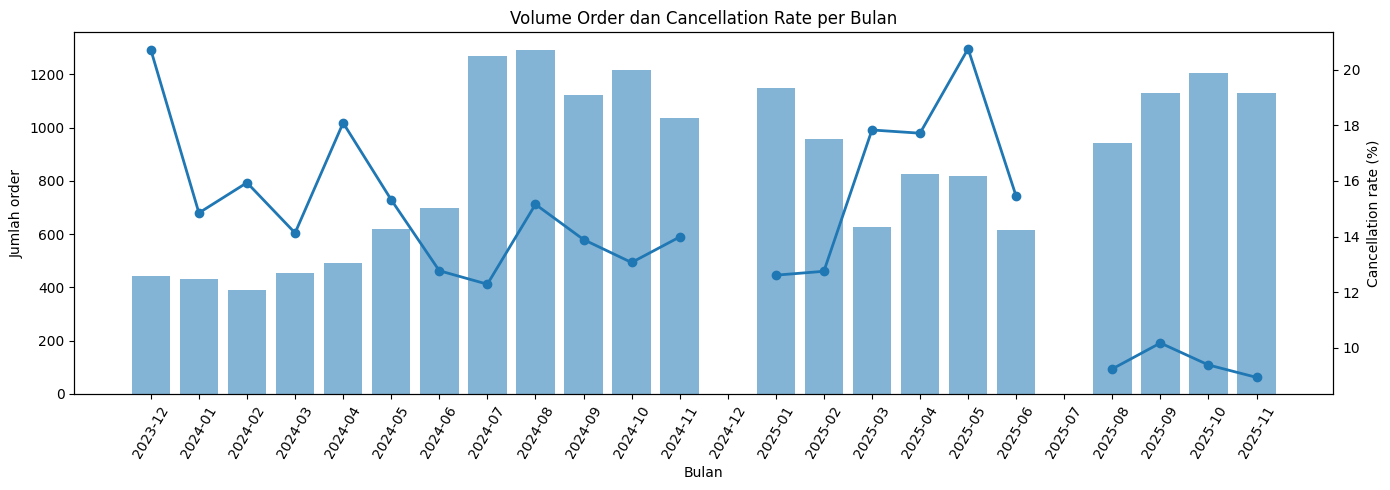

In [9]:
if not monthly.empty:
    fig, ax1 = plt.subplots(figsize=(14, 5))
    x = monthly.index.astype(str)

    ax1.bar(x, monthly["total_orders"], alpha=0.55, label="Total orders")
    ax1.set_ylabel("Jumlah order")
    ax1.set_xlabel("Bulan")
    ax1.tick_params(axis="x", rotation=60)

    ax2 = ax1.twinx()
    ax2.plot(x, monthly["cancellation_rate_pct"], marker="o",
             linewidth=2, label="Cancellation rate")
    ax2.set_ylabel("Cancellation rate (%)")

    ax1.set_title("Volume Order dan Cancellation Rate per Bulan")
    fig.tight_layout()
    plt.show()


## 7. Analisis pembatalan menurut metode pembayaran dan provinsi

Rate per kelompok harus dibaca bersama jumlah order (`n`). Hindari menyimpulkan dari kelompok dengan sampel sangat kecil.


In [10]:
def cancellation_by_dimension(data, column, min_orders=30):
    temp = data[[ "order_id", "status_normalized", column ]].copy()
    temp[column] = temp[column].astype("string").fillna("Unknown").str.strip()
    out = (
        temp.groupby(column, dropna=False)
            .agg(
                total_orders=("order_id", "nunique"),
                cancelled_orders=("status_normalized", lambda s: s.eq("Batal").sum())
            )
    )
    out["cancellation_rate_pct"] = (
        out["cancelled_orders"] / out["total_orders"] * 100
    )
    out["meets_min_sample"] = out["total_orders"] >= min_orders
    return out.sort_values(
        ["meets_min_sample", "cancellation_rate_pct", "total_orders"],
        ascending=[False, False, False]
    )

payment_cancel = cancellation_by_dimension(df, "payment_method_analysis", min_orders=30)
province_cancel = cancellation_by_dimension(df, "Provinsi", min_orders=30)

display(payment_cancel.head(15))
display(province_cancel.head(15))


,total_orders,cancelled_orders,cancellation_rate_pct,meets_min_sample
payment_method_analysis,,,,
Alfamart/Alfamidi/Dan+Dan,34,16,47.058824,True
Indomaret/i.Saku,38,17,44.736842,True
online payment,30,7,23.333333,True
Online Payment,2754,516,18.736383,True
SPayLater,1303,200,15.349194,True
SPay Later,33,5,15.151515,True
COD,103,15,14.563107,True
SeaBank Bayar Instan,574,80,13.937282,True
COD (Bayar di Tempat),10100,1359,13.455446,True


,total_orders,cancelled_orders,cancellation_rate_pct,meets_min_sample
Provinsi,,,,
SULAWESI UTARA,38,13,34.210526,True
SULAWESI TENGAH,49,16,32.653061,True
KALIMANTAN TIMUR,129,37,28.682171,True
NUSA TENGGARA BARAT (NTB),97,27,27.835052,True
KALIMANTAN TENGAH,123,31,25.203252,True
KEPULAUAN RIAU,66,16,24.242424,True
NANGGROE ACEH DARUSSALAM (NAD),119,28,23.529412,True
SULAWESI SELATAN,217,48,22.119816,True
GORONTALO,48,10,20.833333,True


## 8. Alasan pembatalan dan kategori produk

Alasan pembatalan diringkas **hanya di antara order batal**. Kategori produk dipisah dengan `explode`; metrik yang dihasilkan adalah jumlah order unik yang memuat kategori, bukan jumlah unit produk.


In [11]:
reason_counts = (
    cancelled["Alasan Pembatalan"]
      .astype("string").fillna("Unknown").str.strip()
      .value_counts()
      .rename_axis("alasan_pembatalan")
      .reset_index(name="jumlah_order_batal")
)
display(reason_counts.head(15))

category_long = (
    df[["order_id", "product_categories"]]
      .assign(category=lambda x: x["product_categories"].astype("string").str.split(r"\s*,\s*"))
      .explode("category")
)
category_long["category"] = category_long["category"].str.strip()
category_long = category_long.dropna(subset=["category"])
category_counts = (
    category_long.groupby("category")["order_id"]
      .nunique()
      .sort_values(ascending=False)
      .rename("jumlah_order_memuat_kategori")
      .head(15)
      .reset_index()
)
display(category_counts)


,alasan_pembatalan,jumlah_order_batal
0,Dibatalkan oleh Pembeli. Alasan: Lainnya/ beru...,604
1,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,500
2,Dibatalkan secara otomatis oleh sistem. Alasan...,403
3,Dibatalkan oleh Pembeli. Alasan: Need to chang...,280
4,Dibatalkan secara otomatis oleh sistem. Alasan...,238
5,Dibatalkan secara otomatis oleh sistem. Alasan...,106
6,Dibatalkan oleh Pembeli. Alasan: Perlu menguba...,103
7,Dibatalkan oleh Pembeli. Alasan: Perlu menguba...,73
8,Dibatalkan secara otomatis oleh sistem. Alasan...,54
9,Dibatalkan oleh Pembeli. Alasan: Lainnya,45


,category,jumlah_order_memuat_kategori
0,Celengan,5420
1,Mangkok Sambal / Saus,3562
2,Aksesoris Pintu,2571
3,Nampan / Tray,1320
4,Other,827
5,Baskom / Mangkok Besar,700
6,Keranjang,652
7,Rak / Rak Serbaguna,642
8,Seal / Baut / Roof,602
9,Lunch Box / Rantang,529


## 9. Insight awal dan ekspor ringkasan untuk AI Agent

Insight di bawah bersifat deskriptif. Perbedaan antar-kelompok bukan bukti sebab-akibat. Agent menerima metrik yang sudah dihitung Python sehingga tidak perlu melakukan aritmetika dari teks mentah.


In [12]:
if not monthly.empty:
    observed_months = monthly[monthly["total_orders"] > 0]
    highest_cancel_month = observed_months["cancellation_rate_pct"].idxmax()
    lowest_cancel_month = observed_months["cancellation_rate_pct"].idxmin()
    print(
        f"Bulan dengan cancellation rate tertinggi: {highest_cancel_month} "
        f"({observed_months.loc[highest_cancel_month, 'cancellation_rate_pct']:.2f}%)."
    )
    print(
        f"Bulan dengan cancellation rate terendah: {lowest_cancel_month} "
        f"({observed_months.loc[lowest_cancel_month, 'cancellation_rate_pct']:.2f}%)."
    )

print(f"Cancellation rate keseluruhan: {kpis['cancellation_rate_pct']:.2f}%.")
print(f"AOV mean order selesai: Rp{kpis['aov_mean_completed']:,.0f}.")
print(f"AOV median order selesai: Rp{kpis['aov_median_completed']:,.0f}.")


Bulan dengan cancellation rate tertinggi: 2025-05 (20.76%).
Bulan dengan cancellation rate terendah: 2025-11 (8.93%).
Cancellation rate keseluruhan: 13.64%.
AOV mean order selesai: Rp59,269.
AOV median order selesai: Rp26,896.


In [14]:
business_summary = {
    "project": "UMKM AI Business Analyst",
    "dataset": "Indonesia E-Commerce Sales (cleaned file supplied)",
    "data_scope_note": (
        "Analisis menggunakan file cleaned. File raw sebelum cleaning tidak tersedia "
        "untuk memverifikasi ulang imputasi dan parsing awal."
    ),
    "definitions": {
        "cancellation_rate": "cancelled unique orders / all unique orders * 100; all statuses included",
        "aov": "mean and median Total Pembayaran for Status Pesanan = Selesai only",
        "category_metric": "unique orders containing each category after splitting multi-category cells"
    },
    "data_quality": {
        "rows": int(len(df)),
        "columns": int(df.shape[1]),
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_order_id": int(df["order_id"].duplicated().sum()),
        "missing_values": {str(k): int(v) for k, v in df.isna().sum().items()},
        "date_parse_failures": int(df["order_date_parsed"].isna().sum()),
        "date_mismatch_count": int(date_mismatch.sum()),
        "qty_missing_count": int(df["qty_missing"].sum())
    },
    "kpis": {str(k): (None if pd.isna(v) else float(v)) for k, v in kpis.items()},
    "monthly": [
        {
            "month": str(idx),
            "total_orders": int(row["total_orders"]),
            "completed_orders": int(row["completed_orders"]),
            "cancelled_orders": int(row["cancelled_orders"]),
            "cancellation_rate_pct": (
                None if pd.isna(row["cancellation_rate_pct"])
                else float(row["cancellation_rate_pct"])
            )
        }
        for idx, row in monthly.iterrows()
    ],
    "cancellation_by_payment_method": [
        {"group": str(idx), "total_orders": int(row["total_orders"]),
         "cancelled_orders": int(row["cancelled_orders"]),
         "cancellation_rate_pct": float(row["cancellation_rate_pct"])}
        for idx, row in payment_cancel.iterrows()
    ],
    "cancellation_by_province_min_n_30": [
        {"group": str(idx), "total_orders": int(row["total_orders"]),
         "cancelled_orders": int(row["cancelled_orders"]),
         "cancellation_rate_pct": float(row["cancellation_rate_pct"])}
        for idx, row in province_cancel[province_cancel["total_orders"] >= 30].iterrows()
    ],
    "cancellation_reasons": [
        {"reason": str(row["alasan_pembatalan"]), "cancelled_orders": int(row["jumlah_order_batal"])}
        for _, row in reason_counts.iterrows()
    ],
    "top_categories_by_unique_orders": [
        {"category": str(row["category"]), "orders": int(row["jumlah_order_memuat_kategori"])}
        for _, row in category_counts.iterrows()
    ]
}

with open("umkm_business_summary_stage1.json", "w", encoding="utf-8") as f:
    import json
    json.dump(business_summary, f, ensure_ascii=False, indent=2)

print("Ringkasan berhasil disimpan: umkm_business_summary_stage1.json")

Ringkasan berhasil disimpan: umkm_business_summary_stage1.json
